# Hartree-Fock per la molecola H₂

In questo notebook risolviamo l'equazione di **Hartree-Fock restricted a guscio chiuso** per H₂, usando una base di **gaussiane primitive non contratte** e calcolando tutti gli integrali in forma analitica. Poi scansioniamo la distanza internucleare $R$ per trovare la lunghezza di legame di equilibrio.

Tutte le grandezze sono in **unità atomiche**: lunghezze in $a_0$ (raggio di Bohr), energie in Hartree.

## 1. Il problema

Con l'approssimazione di Born-Oppenheimer i nuclei A e B sono fermi in $\mathbf R_A$ e $\mathbf R_B$, e l'Hamiltoniana elettronica è

$$
\hat H = \sum_{i=1}^{2}\left[-\tfrac12\nabla_i^2 - \frac{1}{|\mathbf r_i-\mathbf R_A|}-\frac{1}{|\mathbf r_i-\mathbf R_B|}\right]+\frac{1}{r_{12}}
$$

L'energia totale include anche la repulsione nucleare, costante a $R$ fissato:

$$
E_{nuc}=\frac{1}{|\mathbf R_A-\mathbf R_B|}
$$

## 2. Approssimazione Hartree-Fock

I due elettroni occupano lo stesso orbitale spaziale $\psi$ (con spin opposti, determinante di Slater a guscio chiuso). L'orbitale è espanso su una base di $n$ funzioni $\phi_p$:

$$
\psi(\mathbf r)=\sum_{p=1}^{n} C_p\,\phi_p(\mathbf r)
$$

La base **non è ortogonale**, quindi la minimizzazione variazionale dell'energia rispetto a $C$ porta all'equazione di Roothaan generalizzata:

$$
F\,C=S\,C\,\varepsilon
$$

con le matrici

$$
S_{pq}=\int\phi_p\phi_q\,d^3r,\qquad
h_{pq}=\int\phi_p\left(-\tfrac12\nabla^2-\tfrac{1}{|\mathbf r-\mathbf R_A|}-\tfrac{1}{|\mathbf r-\mathbf R_B|}\right)\phi_q\,d^3r
$$

e la matrice di Fock

$$
F_{pq}=h_{pq}+\sum_{rs}D_{rs}\Big[2\,(pq|rs)-(ps|rq)\Big],\qquad D_{rs}=C_rC_s
$$

dove gli integrali a due elettroni sono

$$
(pq|rs)=\iint\frac{\phi_p(1)\phi_q(1)\,\phi_r(2)\phi_s(2)}{r_{12}}\,d1\,d2
$$

Nel codice si usa $P=2\,C\,C^T$ (la matrice densità include il fattore 2 di occupazione), quindi $F=h+\tfrac12 G[P]$.

## 3. Problema non lineare: ciclo SCF

$F$ dipende da $C$ attraverso $P$, quindi si procede per iterazione (**Self-Consistent Field**):

1. si parte da $P=0$ (cioè $F=h$, la *core guess*);
2. si costruisce $F[P]$;
3. si risolve $FC=SC\varepsilon$ e si prende l'orbitale a energia più bassa;
4. si ricalcola $P$ (con un eventuale mixing con la vecchia densità);
5. si ripete finché gli autovalori $\varepsilon$ non cambiano meno di una tolleranza.

All'ultimo passo l'energia è

$$
E=\tfrac12\sum_{pq}P_{pq}\,(h_{pq}+F_{pq})+E_{nuc}=\sum_{pq}P_{pq}\Big(h_{pq}+\tfrac14G_{pq}\Big)+E_{nuc}
$$

## 4. La base

Ogni atomo porta 4 gaussiane di tipo $s$ non normalizzate:

$$
\phi_p(\mathbf r)=e^{-\alpha_p|\mathbf r-\mathbf R_p|^2}
$$

per un totale di $n=8$ funzioni. Con le gaussiane tutti gli integrali hanno forma chiusa grazie al **teorema del prodotto gaussiano**:

$$
e^{-\alpha_p|\mathbf r-\mathbf R_p|^2}e^{-\alpha_q|\mathbf r-\mathbf R_q|^2}=K_{pq}\,e^{-(\alpha_p+\alpha_q)|\mathbf r-\mathbf R_{pq}|^2}
$$

con

$$
\mu_{pq}=\frac{\alpha_p\alpha_q}{\alpha_p+\alpha_q},\qquad
K_{pq}=e^{-\mu_{pq}|\mathbf R_p-\mathbf R_q|^2},\qquad
\mathbf R_{pq}=\frac{\alpha_p\mathbf R_p+\alpha_q\mathbf R_q}{\alpha_p+\alpha_q}
$$

## Import

- `numpy`: array e algebra lineare di base;
- `scipy.linalg`: serve `eigh`, che risolve il problema agli autovalori **generalizzato** $FC=SC\varepsilon$;
- `scipy.special.erf`: la funzione errore, che compare negli integrali di attrazione nucleare e di repulsione elettronica (è la funzione di Boys $F_0$ riscritta);
- `matplotlib`: per il grafico dell'energia in funzione di $R$.

In [30]:
import sys
import numpy as np
import scipy.linalg as la
from scipy.special import erf
import matplotlib.pyplot as plt

## Parametri

- `eps`: soglia sotto cui due punti sono considerati coincidenti. Serve per evitare la divisione $0/0$ in $\mathrm{erf}(x)/x$ quando $x\to0$, dove si usa il limite analitico.
- `pi`: scorciatoia per $\pi$.
- `max_iter`: numero massimo di iterazioni SCF.
- `alpha`: gli **esponenti delle 4 gaussiane** $\alpha_p$ usate su ciascun atomo, dalla più diffusa (0.12) alla più compatta (13.0).

In [31]:
eps=1e-8
pi=np.pi
max_iter=400
alpha = np.array([0.121949, 0.444529, 1.962079, 13.00773])

## Classe `H2`

La classe è divisa in due fasi:

- `__init__` calcola **una volta sola** tutto ciò che dipende solo da geometria e base: $S$, $T$, $V$, $h$, il tensore a due elettroni e $E_{nuc}$;
- `__call__` esegue il **ciclo SCF**, che usa solo quelle quantità già pronte.

I metodi con doppio underscore (`__V`, `__Vpq`, `__Qprqs`, e gli attributi `__S`, `__h`, ...) sono "privati": il name mangling di Python li rende non accessibili dall'esterno con il nome semplice.

### `__init__`: preparazione della base

- `self.n = 2*len(alpha)`: 4 primitive per atomo $\times$ 2 atomi = 8 funzioni.
- `R` è un array $8\times3$: la riga $p$ contiene le coordinate $(x,y,z)$ del centro della gaussiana $p$. Le prime 4 righe sono $\mathbf R_A$, le ultime 4 sono $\mathbf R_B$.
- `normR[p,q]` $=|\mathbf R_p-\mathbf R_q|^2$.
- `__atot[p,q]` $=\alpha_p+\alpha_q$.
- `__ar[p,q]` $=\mu_{pq}=\alpha_p\alpha_q/(\alpha_p+\alpha_q)$.
- `__K[p,q]` $=K_{pq}=e^{-\mu_{pq}|\mathbf R_p-\mathbf R_q|^2}$.
- `__avR[p,q,:]` $=\mathbf R_{pq}$, il centro della gaussiana prodotto (tensore $8\times8\times3$).

### Integrali a un elettrone

**Sovrapposizione**

$$
S_{pq}=K_{pq}\left(\frac{\pi}{\alpha_p+\alpha_q}\right)^{3/2}
$$

**Energia cinetica** ($T_{pq}=-\tfrac12\langle\phi_p|\nabla^2|\phi_q\rangle$)

$$
T_{pq}=\mu_{pq}\Big(3-2\mu_{pq}|\mathbf R_p-\mathbf R_q|^2\Big)S_{pq}
$$

**Attrazione nucleare** verso un nucleo in $\mathbf R_C$ (metodi `__V` e `__Vpq`), con $a=\alpha_p+\alpha_q$ e $d=|\mathbf R_{pq}-\mathbf R_C|$:

$$
V_{pq}^{(C)}=-\frac{S_{pq}}{d}\,\mathrm{erf}\!\big(\sqrt{a}\,d\big)\quad(d>0),\qquad
V_{pq}^{(C)}\xrightarrow{d\to0}-\frac{2\pi}{a}K_{pq}
$$

**Hamiltoniano di core**: $h=T+V_A+V_B$.

### Integrali a due elettroni

Per il prodotto di due gaussiane $pq$ e $rs$, con $\gamma=\sqrt{\dfrac{(\alpha_p+\alpha_q)(\alpha_r+\alpha_s)}{\alpha_p+\alpha_q+\alpha_r+\alpha_s}}$ e $d=|\mathbf R_{pq}-\mathbf R_{rs}|$:

$$
(pq|rs)=\frac{S_{pq}S_{rs}}{d}\,\mathrm{erf}(\gamma d)\quad(d>0),\qquad
(pq|rs)\xrightarrow{d\to0}\frac{2\gamma}{\sqrt\pi}S_{pq}S_{rs}
$$

I $n^4=4096$ integrali sono memorizzati in `Q[p,r,q,s]` $=(pq|rs)$. Per funzioni reali valgono 8 simmetrie

$$
(pq|rs)=(qp|rs)=(pq|sr)=(qp|sr)=(rs|pq)=(sr|pq)=(rs|qp)=(sr|qp)
$$

quindi i quattro cicli annidati calcolano solo gli integrali indipendenti (con $p\ge q$, $r\ge s$, $(pq)\ge(rs)$), e `__Qprqs` scrive il valore in tutte le 8 posizioni equivalenti.

**Tensore di Coulomb e scambio**

```python
self.__G = 2.*Q - np.transpose(Q, (0,1,3,2))
```

contratto con $P$ dà

$$
G_{ik}=\sum_{ab}P_{ab}\Big[2\,(ik|ab)-(ib|ak)\Big]
$$

cioè il doppio del termine di Coulomb meno il termine di scambio.

**Repulsione nucleare**: $E_{nuc}=1/|\mathbf R_A-\mathbf R_B|$. Il codice assume $Z=1$ per entrambi i nuclei (H₂).

### `__call__`: ciclo SCF

Ad ogni iterazione:

1. `G = tensordot(Pi, __G, ...)` costruisce $G[P_{prec}]$;
2. `F = h + 0.5*G` è la matrice di Fock;
3. `eigh(F, b=S)` risolve $FC=SC\varepsilon$ e restituisce gli autovalori in ordine crescente;
4. `P = alpha*2*outer(v0, v0) + (1-alpha)*Pi`: la nuova densità è costruita dall'orbitale occupato (il più basso), con un eventuale **mixing** (`alpha<1` smorza le oscillazioni);
5. se un autovalore è cambiato più di `accuracy` rispetto al passo precedente, si richiama `self(...)` con la nuova $P$ (ricorsione);
6. altrimenti si salva $C$ e si calcola $E=\sum P(h+G/4)+E_{nuc}$.

Il metodo ritorna `(E, C, numero di iterazioni)`.

In [32]:
class H2:
    def __init__(self, alpha, RA, RB):
        self.n = 2*len(alpha) #number of basis functions (2*number of primitive gaussians beacause we have 2 atoms)
        self.w = np.zeros(self.n) #eigenvalues of the Fock matrix
        self.C = np.zeros(self.n) #eigenvectors of the Fock matrix
        self.E = 0. #total energy of the system
        self.__alpha = np.concatenate((alpha, alpha)) #exponents of the primitive gaussians (a_1, a_2, a_3, a_4, a_1, a_2, a_3, a_4)
        R = np.array([RA, RA, RA, RA, RB, RB, RB, RB]) # centers of the primitive gaussians (4 for atom A and 4 for atom B) (8,3) array
        normR = np.array([[np.linalg.norm(Rp-Rq)**2 for Rq in R] for Rp in R]) #distance matrix between the centers of the primitive gaussians
    
        a = np.array([self.__alpha for i in range(self.n)]) 
        self.__atot = a + a.T #matrix of the sum of the exponents of the primitive gaussians a_pq = a_p + a_q
        self.__ar = np.tensordot(self.__alpha,self.__alpha,axes=0)/self.__atot # mu_pq = a_p * a_q / (a_p + a_q)
        self.__K = np.exp(-normR*self.__ar) # K matrix = exp(-|R_p - R_q|^2 * mu_pq) we need this for the overlap, kinetic matrix

        a = np.array([(R.T*self.__alpha).T for i in range(self.n)]) # a_p R_p 
        self.__avR = a + np.transpose(a, (1,0,2)) # a_p R_p + a_q R_q
        for b in self.__avR.T: b /= self.__atot # avR = (a_p R_p + a_q R_q) / (a_p + a_q)

        # overlap matrix
        self.__S = self.__K*(pi/self.__atot)**1.5
        # kinetic matrix
        self.__T = self.__ar*(3. - 2.*self.__ar*normR)*self.__S
        # nuclear matrix
        self.__h = self.__T + self.__V(RA) + self.__V(RB)
        # two electrons matrix
        Q = np.zeros((self.n, self.n, self.n, self.n))
        for p in range(self.n):
            for q in range(p+1):
                for r in range(p):
                    for s in range(r+1):
                        self.__Qprqs(Q,p,r,q,s)
                r=p
                for s in range(q+1):
                    self.__Qprqs(Q,p,r,q,s)
        self.__G = 2.*Q - np.transpose(Q, (0,1,3,2))
        # nuclear repulsion energy
        self.__E_nuc = 1./np.linalg.norm(RA-RB)
        self.it = 1

    def __call__(self, accuracy, Pi=None, alpha=1., wprev=None, max_iter=900):
        if self.it > max_iter: sys.exit('Maximum number of iteration has been '
                'reached -> Abort.')
        if Pi is None: Pi = np.zeros((self.n, self.n))
        if wprev is None: wprev = np.zeros(self.n)
        G = np.tensordot(Pi, self.__G, axes=([0,1], [1,3]))
        F = self.__h + .5*G
        self.w, v = la.eigh(F, b=self.__S)
        P = alpha*2.*np.tensordot(v.T[0], v.T[0], axes=0) + (1-alpha)*Pi
        for wk, wkp in zip(self.w, wprev):
            if abs(wk-wkp) > accuracy:
                self.it += 1
                return self(accuracy, P, alpha, self.w, max_iter)
        self.C = v.T[0]
        self.E = np.tensordot(P, self.__h+.25*G, axes=([0,1],[0,1])) + self.__E_nuc
        return self.E, self.C, self.it

    def __V(self, R):
        V = np.zeros((self.n, self.n))
        for p in range(self.n):
            for q in range(p+1):
                V[p,q] = self.__Vpq(R, p, q)
                V[q,p] = V[p,q]
        return V

    def __Vpq(self, R, p, q):
        eqR = np.linalg.norm(self.__avR[p,q]-R)
        if eqR > eps: return -self.__S[p,q]/eqR*erf(eqR*self.__atot[p,q]**.5)
        else: return -2.*pi/self.__atot[p,q]*self.__K[p,q]

    def __Qprqs(self, Q, p, r, q, s):
        rr = np.linalg.norm(self.__avR[p,q]-self.__avR[r,s])
        a = np.sqrt((self.__alpha[p] + self.__alpha[q])*(self.__alpha[r] +
            self.__alpha[s])/(self.__alpha[p] + self.__alpha[q] +
                self.__alpha[r] + self.__alpha[s]))
        if rr > eps: qq = self.__S[p,q]*self.__S[r,s]/rr*erf(rr*a)
        else: qq = 2.*self.__S[p,q]*self.__S[r,s]*a/pi**.5
        # exploit full S_4's subgroup that contains Q symmetries
        Q[p,r,q,s] = qq
        Q[q,r,p,s] = qq
        Q[r,p,s,q] = qq
        Q[r,q,s,p] = qq
        Q[p,s,q,r] = qq
        Q[q,s,p,r] = qq
        Q[s,p,r,q] = qq
        Q[s,q,r,p] = qq

## Curva di energia e lunghezza di legame

**1. Scansione.** Si fissa $\mathbf R_A=(0,0,0)$ e si sposta $\mathbf R_B=(R,0,0)$ da 0.3 a 6 $a_0$ con passo 0.01. Per ogni $R$:

- si costruisce un oggetto `H2` (ricalcolando tutti gli integrali, che dipendono dalla geometria);
- si esegue l'SCF con tolleranza $10^{-6}$ sugli autovalori;
- si salva l'energia totale $E(R)=E_{el}+E_{nuc}$.

I dati sono scritti in `bonding_energy.txt` e il grafico in `bonding_energy.pdf`.

**2. Equilibrio.** La lunghezza di legame è il minimo di $E(R)$:

$$
R_{eq}=\underset{R}{\mathrm{argmin}}\;E(R)
$$

Per $R\to0$ domina la repulsione nucleare $1/R$; per $R\to\infty$ l'energia tende a quella di due atomi separati. Il minimo in mezzo è il legame chimico. Il valore sperimentale è $R_{eq}\approx1.4\,a_0$, con energia totale circa $-1.17$ Hartree. Il risultato Hartree-Fock sarà un po' più alto, perché HF non include la correlazione elettronica.

**3. Stato fondamentale.** Si ricostruisce la molecola alla distanza di equilibrio e si stampano l'autovalore più basso $\varepsilon_0$ (energia dell'orbitale molecolare occupato), i coefficienti $C_p$ dell'orbitale e il numero di iterazioni SCF necessarie.

##################################################
#            molecule's bond length
##################################################

Equilibrium bonding energy:  -1.1265440749382833  (Hartree)
Equilibrium bond length:  1.390000000000001  (a0)

##################################################
# ground state eigenvalue and eigenvector of the
# Fock operator in the equilibrium configuration
##################################################

eigenvalue:  -0.5968407299844685
eigenvector:  [0.02646987 0.12298676 0.13280335 0.0787844  0.02646987 0.12298676
 0.13280335 0.0787844 ]
number of iteration:  11 



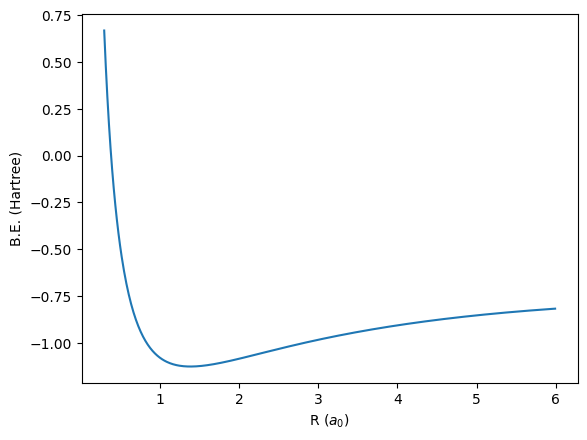

In [33]:

print('##################################################')
print('#            molecule\'s bond length')
print('##################################################\n')
RA = np.array([0., 0., 0.])
RBx = np.arange(0.3, 6., 0.01)  # initial R, final R, stepsize
E = np.zeros(len(RBx))
text = ''
for i, RBxi in enumerate(RBx):
    RB = np.array([RBxi, 0., 0.])
    h2i = H2(alpha, RA, RB)
    E[i] = h2i(1e-6)[0]
    text += str(RBxi) + ' ' + str(h2i.E) + '\n'
# store data on a file
with open('bonding_energy.txt', 'w+') as f:
    f.write(text)
del text
# plot
plt.plot(RBx, E)
plt.xlabel('R ($a_0$)')
plt.ylabel('B.E. (Hartree)')
plt.savefig('bonding_energy.pdf')
# equilibrium bonding length
i = np.argmin(E)
print('Equilibrium bonding energy: ', E[i], ' (Hartree)')
print('Equilibrium bond length: ', RBx[i], ' (a0)')

print('\n##################################################')
print('# ground state eigenvalue and eigenvector of the')
print('# Fock operator in the equilibrium configuration')
print('##################################################\n')
RB = np.array([RBx[i], 0., 0.])
h2 = H2(alpha, RA, RB)
h2(1e-6)
print('eigenvalue: ', h2.w[0])
print('eigenvector: ', h2.C)
print('number of iteration: ', h2.it, '\n')
